In [9]:
# 1) importando libs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

In [10]:
# 2) extraindo os .csv (base tratada)
pasta = "database/"
motos = pd.read_csv(pasta + "motos.csv")
clientes = pd.read_csv(pasta + "clientes.csv")
locacoes = pd.read_csv(pasta + "locacoes.csv")
manutencoes = pd.read_csv(pasta + "manutencoes.csv")
locacoes.head()

,id_locacao,id_moto,id_cliente,data_retirada,data_devolucao_prevista,data_devolucao_real,plano,valor_diaria,valor_total,forma_pagamento,status_pagamento,km_retirada,km_devolucao,filial_retirada,status_locacao
0,L00001,M015,C0327,30/06/2023,14/07/2023,14/07/2023,Semanal,76.50,1071.00,Dinheiro,Pago,7190.0,8884.0,São Paulo,Finalizada
1,L00002,M090,C0331,14/07/2023,04/08/2023,04/08/2023,Semanal,80.75,1695.75,Cartão de Crédito,Atrasado,6050.0,7982.0,João Pessoa,Finalizada
2,L00003,M051,C0553,15/07/2023,05/08/2023,05/08/2023,Semanal,76.50,1606.50,Pix,Pago,8378.0,9932.0,São Paulo,Finalizada
3,L00004,M015,C0441,20/07/2023,18/09/2023,21/09/2023,Mensal,63.00,4063.50,Pix,Pago,8884.0,16759.0,São Paulo,Finalizada
4,L00005,M054,C0279,03/08/2023,02/09/2023,04/09/2023,Mensal,63.00,2079.00,Boleto,Pendente,6871.0,9463.0,João Pessoa,Finalizada


In [11]:
# 3) convertendo as colunas de data (formato dd/mm/aaaa) para datetime
motos["data_aquisicao"] = pd.to_datetime(motos["data_aquisicao"], format="%d/%m/%Y")
clientes["data_cadastro"] = pd.to_datetime(clientes["data_cadastro"], format="%d/%m/%Y")
clientes["data_nascimento"] = pd.to_datetime(clientes["data_nascimento"], format="%d/%m/%Y")
for col in ["data_retirada", "data_devolucao_prevista", "data_devolucao_real"]:
    locacoes[col] = pd.to_datetime(locacoes[col], format="%d/%m/%Y")
manutencoes["data_manutencao"] = pd.to_datetime(manutencoes["data_manutencao"], format="%d/%m/%Y")

# data de referência das consultas (a mesma usada na documentação do projeto)
data_ref = pd.Timestamp("2026-11-10")
locacoes.dtypes

id_locacao                         object
id_moto                            object
id_cliente                         object
data_retirada              datetime64[ns]
data_devolucao_prevista    datetime64[ns]
data_devolucao_real        datetime64[ns]
plano                              object
valor_diaria                      float64
valor_total                       float64
forma_pagamento                    object
status_pagamento                   object
km_retirada                       float64
km_devolucao                      float64
filial_retirada                    object
status_locacao                     object
dtype: object

In [12]:
# 4) volumes: quantidade de linhas e colunas de cada tabela
volumes = pd.DataFrame({
    "linhas": [len(motos), len(clientes), len(locacoes), len(manutencoes)],
    "colunas": [motos.shape[1], clientes.shape[1], locacoes.shape[1], manutencoes.shape[1]],
}, index=["motos", "clientes", "locacoes", "manutencoes"])
volumes

,linhas,colunas
motos,120,11
clientes,700,10
locacoes,4201,15
manutencoes,1361,8


In [13]:
# 5) período coberto por cada tabela (primeira e última data) e quantos meses isso representa
periodo = pd.DataFrame({
    "inicio": [motos["data_aquisicao"].min(), clientes["data_cadastro"].min(),
               locacoes["data_retirada"].min(), manutencoes["data_manutencao"].min()],
    "fim": [motos["data_aquisicao"].max(), clientes["data_cadastro"].max(),
            locacoes["data_retirada"].max(), manutencoes["data_manutencao"].max()],
}, index=["motos (aquisição)", "clientes (cadastro)", "locacoes (retirada)", "manutencoes (data)"])
periodo["meses"] = ((periodo["fim"] - periodo["inicio"]).dt.days / 30.44).round(1)
periodo

,inicio,fim,meses
motos (aquisição),2023-06-19,2025-12-17,30.0
clientes (cadastro),2023-06-13,2026-10-29,40.5
locacoes (retirada),2023-06-30,2026-11-01,40.1
manutencoes (data),2023-07-09,2026-10-31,39.8


In [14]:
# 6) relação entre as tabelas: cardinalidade (1 moto -> N locações, 1 cliente -> N locações, 1 moto -> N manutenções)
loc_por_moto = locacoes.groupby("id_moto").size()
loc_por_cliente = locacoes.groupby("id_cliente").size()
man_por_moto = manutencoes.groupby("id_moto").size()
pd.DataFrame({
    "media": [loc_por_moto.mean(), loc_por_cliente.mean(), man_por_moto.mean()],
    "minimo": [loc_por_moto.min(), loc_por_cliente.min(), man_por_moto.min()],
    "maximo": [loc_por_moto.max(), loc_por_cliente.max(), man_por_moto.max()],
    "sem nenhum registro": [(~motos["id_moto"].isin(locacoes["id_moto"])).sum(),
                            (~clientes["id_cliente"].isin(locacoes["id_cliente"])).sum(),
                            (~motos["id_moto"].isin(manutencoes["id_moto"])).sum()],
}, index=["locações por moto", "locações por cliente", "manutenções por moto"]).round(1)

,media,minimo,maximo,sem nenhum registro
locações por moto,35.0,8,67,0
locações por cliente,7.4,1,44,136
manutenções por moto,11.3,4,19,0


In [15]:
# 7) relação entre as tabelas: a filial de retirada da locação bate com a filial da moto?
loc_moto = locacoes.merge(motos[["id_moto", "filial"]], on="id_moto")
print("Locações com filial de retirada diferente da filial da moto:", (loc_moto["filial"] != loc_moto["filial_retirada"]).sum())

Locações com filial de retirada diferente da filial da moto: 0


## P1 - rentabilidade (receita, ticket médio, receita líquida e ROI)

In [16]:
# 8) separando as locações não canceladas (só elas geram receita)
loc_ok = locacoes[locacoes["status_locacao"] != "Cancelada"].copy()
print("Locações totais:", len(locacoes), "| canceladas:", (locacoes["status_locacao"] == "Cancelada").sum(),
      "| não canceladas:", len(loc_ok))

Locações totais: 4201 | canceladas: 117 | não canceladas: 4084


In [17]:
# 9) receita total e ticket médio por locação
# receita total = soma de valor_total | ticket médio = receita total / nº de locações não canceladas
receita_total = loc_ok["valor_total"].sum()
ticket_medio = receita_total / len(loc_ok)
print(f"Receita total: R$ {receita_total:,.2f}")
print(f"Ticket médio por locação: R$ {ticket_medio:,.2f}")

Receita total: R$ 5,374,155.74
Ticket médio por locação: R$ 1,315.90


In [18]:
# 10) receita líquida e ROI por moto
# receita líquida = receita da moto - custo de manutenção da moto | ROI = receita líquida / valor de aquisição
receita_moto = loc_ok.groupby("id_moto")["valor_total"].sum().rename("receita")
custo_moto = manutencoes.groupby("id_moto")["custo"].sum().rename("custo_manutencao")

rentab = (motos.set_index("id_moto")[["modelo", "filial", "valor_aquisicao"]]
          .join(receita_moto).join(custo_moto).fillna({"receita": 0, "custo_manutencao": 0}))
rentab["receita_liquida"] = rentab["receita"] - rentab["custo_manutencao"]
rentab["roi"] = rentab["receita_liquida"] / rentab["valor_aquisicao"]
rentab.head()

,modelo,filial,valor_aquisicao,receita,custo_manutencao,receita_liquida,roi
id_moto,,,,,,,
M001,Yamaha Factor 150,São Paulo,15808.74,34956.00,2773.08,32182.92,2.035768
M002,Honda CG 160 Titan,João Pessoa,15869.92,20199.38,1802.94,18396.44,1.159202
M003,Honda Biz 125,São Paulo,14243.00,19809.37,1173.38,18635.99,1.308432
M004,Yamaha Factor 150,São Paulo,16194.86,52305.75,4734.48,47571.27,2.937430
M005,Honda CG 160 Fan,São Paulo,15660.98,23589.00,1414.73,22174.27,1.415893


In [19]:
# 11) ROI mensal: o ROI acumulado favorece as motos mais antigas (tiveram mais meses para gerar receita)
# para comparar motos de idades diferentes, dividimos o ROI pelos meses em que a moto está na frota
rentab["meses_frota"] = (data_ref - motos.set_index("id_moto")["data_aquisicao"]).dt.days / 30.44
rentab["roi_mensal"] = rentab["roi"] / rentab["meses_frota"]
print("Correlação entre ROI acumulado e meses na frota:", round(rentab["roi"].corr(rentab["meses_frota"]), 2))
rentab[["roi", "meses_frota", "roi_mensal"]].describe().round(3)

Correlação entre ROI acumulado e meses na frota: 0.97


,roi,meses_frota,roi_mensal
count,120.000,120.000,120.000
mean,2.662,25.727,0.104
std,0.933,8.766,0.010
min,1.058,10.775,0.081
25%,1.899,18.257,0.098
50%,2.643,25.115,0.103
75%,3.386,33.344,0.109
max,4.669,40.736,0.136


In [20]:
# 12) as 5 motos MAIS e as 5 MENOS rentáveis (pelo ROI mensal)
display(rentab.nlargest(5, "roi_mensal").round(3)) #mais
display(rentab.nsmallest(5, "roi_mensal").round(3)) #menos

,modelo,filial,valor_aquisicao,receita,custo_manutencao,receita_liquida,roi,meses_frota,roi_mensal
id_moto,,,,,,,,,
M017,Yamaha NMAX 160,São Paulo,18737.49,28100.25,706.60,27393.65,1.462,10.775,0.136
M084,Yamaha NMAX 160,João Pessoa,19769.84,54978.76,3676.42,51302.34,2.595,19.711,0.132
M079,Honda CG 160 Titan,São Paulo,15458.11,27994.13,2969.59,25024.54,1.619,12.582,0.129
M091,Honda CG 160 Fan,João Pessoa,14941.90,35419.50,3140.26,32279.24,2.160,17.346,0.125
M037,Yamaha NMAX 160,São Paulo,20296.96,55063.12,4957.78,50105.34,2.469,20.039,0.123


,modelo,filial,valor_aquisicao,receita,custo_manutencao,receita_liquida,roi,meses_frota,roi_mensal
id_moto,,,,,,,,,
M065,Honda Pop 110i,São Paulo,11830.70,24958.37,5180.37,19778.00,1.672,20.696,0.081
M013,Shineray Jet 125,João Pessoa,9874.76,34834.50,10817.26,24017.24,2.432,30.026,0.081
M050,Honda Biz 125,São Paulo,13091.59,19379.27,2092.79,17286.48,1.320,15.867,0.083
M031,Honda Biz 125,João Pessoa,13787.15,23778.76,2608.35,21170.41,1.536,17.707,0.087
M061,Honda Pop 110i,João Pessoa,11702.88,28791.74,5201.50,23590.24,2.016,23.127,0.087


In [21]:
# 13) rentabilidade agregada por modelo e por filial
# ROI do grupo = receita líquida total / valor de aquisição total (assim motos caras pesam mais)
# ROI mensal do grupo (%) = receita líquida total / soma(valor de aquisição x meses na frota) x 100
def resumo_rentab(g):
    return pd.Series({"motos": len(g), "receita": g["receita"].sum(),
                      "receita_liquida": g["receita_liquida"].sum(),
                      "receita_liq_por_moto": g["receita_liquida"].mean(),
                      "meses_frota_medio": g["meses_frota"].mean(),
                      "roi": g["receita_liquida"].sum() / g["valor_aquisicao"].sum(),
                      "roi_mensal_%": g["receita_liquida"].sum() / (g["valor_aquisicao"] * g["meses_frota"]).sum() * 100})

colunas = ["receita", "receita_liquida", "valor_aquisicao", "meses_frota"]
por_modelo = rentab.groupby("modelo")[colunas].apply(resumo_rentab).sort_values("roi_mensal_%", ascending=False)
por_filial = rentab.groupby("filial")[colunas].apply(resumo_rentab)
display(por_modelo.round(2))
display(por_filial.round(2))

,motos,receita,receita_liquida,receita_liq_por_moto,meses_frota_medio,roi,roi_mensal_%
modelo,,,,,,,
Yamaha NMAX 160,3.0,138142.13,128801.33,42933.78,16.84,2.19,12.90
Honda PCX 160,3.0,137793.50,125643.49,41881.16,19.52,2.19,11.22
Yamaha Factor 150,17.0,876804.75,802390.88,47199.46,28.58,3.10,10.88
Yamaha Fazer 250,4.0,348154.86,330068.11,82517.03,32.47,3.50,10.75
Honda CG 160 Fan,20.0,943388.50,860037.24,43001.86,26.21,2.76,10.54
Honda NXR 160 Bros,7.0,415178.50,382732.12,54676.02,26.89,2.77,10.34
Honda CG 160 Titan,26.0,1097527.95,998066.30,38387.17,23.01,2.36,10.26
Shineray Jet 125,7.0,198270.00,167555.86,23936.55,24.19,2.41,9.97
Honda Biz 125,19.0,729316.20,652940.11,34365.27,26.07,2.58,9.92


,motos,receita,receita_liquida,receita_liq_por_moto,meses_frota_medio,roi,roi_mensal_%
filial,,,,,,,
João Pessoa,68.0,3138587.28,2851595.07,41935.22,26.07,2.73,10.4
São Paulo,52.0,2235568.46,2020442.18,38854.66,25.28,2.59,10.4


NameError: name 'AZUL' is not defined

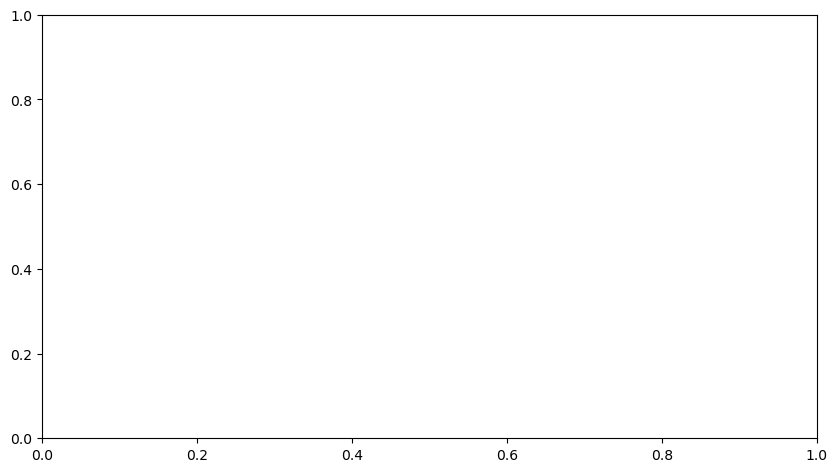

In [ ]:
# 14) GRÁFICO 1 (P1) - ROI mensal por modelo de moto
fig, ax = plt.subplots(figsize=(10, 5.5))
dados = por_modelo["roi_mensal_%"].sort_values()      # em % ao mês
barras = ax.barh(dados.index, dados.values, color="#2a78d6", height=0.6)
ax.bar_label(barras, labels=[f"{v:.1f}%".replace(".", ",") for v in dados.values], padding=4,
             color="#52514e", fontsize=9, bbox=dict(fc="#fcfcfb", ec="none", pad=0.6))
roi_frota = rentab["receita_liquida"].sum() / (rentab["valor_aquisicao"] * rentab["meses_frota"]).sum() * 100
ax.axvline(roi_frota, color="#52514e", ls="--", lw=1, zorder=1)
ax.text(roi_frota, -0.75, f" média da frota: {roi_frota:.1f}% ao mês".replace(".", ","), color="#52514e", fontsize=9, va="center")
ax.set_ylim(-1.1, len(dados) - 0.4)
ax.set_xlabel("ROI mensal (receita líquida ÷ valor de aquisição ÷ meses na frota, %)")
ax.set_title("P1 - Retorno mensal sobre o valor de aquisição por modelo")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, dados.max() * 1.15)
plt.tight_layout()
plt.show()

## Primeiras conclusões (para validação)

**Base**
- Volumes da base tratada: 120 motos, 702 clientes, 4.201 locações e 1.361 manutenções.
- Período: as locações vão de 30/06/2023 a 01/11/2026 (cerca de 40 meses). As motos foram compradas entre 06/2023 e 12/2025.
- Relação entre as tabelas: nenhuma chave órfã. Cada moto tem de 8 a 67 locações e de 4 a 19 manutenções. 136 clientes estão cadastrados mas nunca alugaram.

**P1 - Rentabilidade**
- Receita total de R$ 5,37 milhões, com ticket médio de R$ 1.315,90 por locação.
- O ROI acumulado depende quase só da idade da moto (correlação de 0,97 com os meses na frota). Por isso a comparação usa o **ROI mensal**.
- A frota devolve em média 10,4% do valor de compra por mês. O melhor modelo é o Yamaha NMAX 160 (12,9% ao mês) e os piores são o Honda Pop 110i (9,5%) e o Biz 125 (9,9%).
- As duas filiais empatam no ROI mensal (10,4%). João Pessoa fatura mais porque tem mais motos (68 contra 52).